# Рекомендации комиксов Goodreads
Выполнил: Загатин Даниил Ильич 517 группа



# Задача

По истории оценок читателя нужно составить список из 10 комиксов, которые он ещё не оценивал. Используется полный датасет Goodreads Comics & Graphic с отзывами и метаданными книг. Оценки 4 и 5 считаются положительными и определяют релевантные книги при оценке рекомендаций.

Сравниваются пять моделей: ItemKNN, iALS, SLIM, FM и iALS с новым таргетом. В FM используются признаки книг, например автор, язык и год публикации. Новый таргет iALS учитывает величину оценки и её давность. Цель сравнения состоит в том, чтобы проверить, помогают ли эти изменения улучшить рекомендации.

Данные разделены по времени на train, validation и test. Модели обучаются только на train, настройки выбираются по validation, а итоговое качество оценивается на test. Из рекомендаций исключаются книги, которые пользователь уже оценивал в train.

Основная метрика NDCG@10 учитывает, попали ли релевантные книги в первые 10 рекомендаций и насколько высоко они стоят. Дополнительная Recall@10 показывает, какую долю релевантных книг удалось найти в этом списке.

**Запуск в Colab:** выберите GPU T4 и выполните все ячейки. Ноутбук распакует код, установит зависимости и скачает два полных архива с отзывами и метаданными. Затем выполнятся подготовка данных, подбор параметров и сравнение моделей. При повторном запуске уже скачанные файлы используются снова. Подробности запуска и описание файлов находятся в `README.md`.


In [1]:
#@title Подготовка кода и зависимостей. Выполнить первой
import base64
import hashlib
import importlib.util
import io
import json
import os
from pathlib import Path, PurePosixPath
import subprocess
import sys
import zipfile

SOURCE_ZIP_B64 = r"""..."""
SOURCE_ZIP_SHA256 = "7e020b0b98e7133caa772b801319ea59daf9522b67faf3b35bf604a4164bb0ad"
SOURCE_MANIFEST = json.loads(r"""{
  "experiment.py": {
    "bytes": 44701,
    "sha256": "c34cf6e5d991799eab9fa506c7cd39326ad06cec425f0e5754e03f9b7450a40c"
  },
  "final_train_only.py": {
    "bytes": 11973,
    "sha256": "38aeb1f6b945e1e0eeb1b31d3dd5555a60924f94da5e5e82c13a9511fc26677d"
  },
  "models/__init__.py": {
    "bytes": 0,
    "sha256": "e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855"
  },
  "models/custom_ials.py": {
    "bytes": 2732,
    "sha256": "1d98bbbaba18430226cf5e4ea3d211996612b2e656a006f9d3894cb18fc25774"
  },
  "models/fm.py": {
    "bytes": 13097,
    "sha256": "d56da8e19329e106ad2c00c5395f0721e8fd33feafd1d007ca1666cfad1bc284"
  },
  "models/ials.py": {
    "bytes": 8854,
    "sha256": "4f0e0e2cf684826c26cde10d5fb9e5ea985abaa3527e7f6a2dab104dfd3761f7"
  },
  "models/item_knn.py": {
    "bytes": 5512,
    "sha256": "54e4e9884d2da8a56d8e2d49375d0b04462a7fa78ca801baccc7e98759930c1c"
  },
  "models/slim.py": {
    "bytes": 11044,
    "sha256": "84742d91aa45e7b1f2165d278b2dcc977baeff46a3cfa09789592ef778c20c0b"
  },
  "utils/__init__.py": {
    "bytes": 0,
    "sha256": "e3b0c44298fc1c149afbf4c8996fb92427ae41e4649b934ca495991b7852b855"
  },
  "utils/data.py": {
    "bytes": 10567,
    "sha256": "f51a57436428f2d1944fcf925f2b37b8b0e062a7042e7f005755bc28ba9a14a3"
  },
  "utils/evaluation.py": {
    "bytes": 5501,
    "sha256": "e552493a4632cbd45bc44b5548a90fe377036ac022426a2dd947db2b48afffd3"
  },
  "utils/features.py": {
    "bytes": 4386,
    "sha256": "7b71441fdc4408e531ba36bbd5b9725954a3e2ccb7e4f8b9624b41c2e8593b28"
  },
  "utils/splitting.py": {
    "bytes": 4977,
    "sha256": "dfa447e4791c67501b447cb1b5085b4aca3baa0813e23544c14a093c88d85611"
  }
}""")

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False



local_candidates = [Path.cwd(), Path.cwd() / "hw1", Path.cwd() / "recsys_hw1"]
local_project = next((p for p in local_candidates
                      if (p / "models").is_dir() and (p / "utils").is_dir()
                      and (p / "experiment.py").is_file() and (p / "final_train_only.py").is_file()), None)
USE_LOCAL_SOURCES = not IN_COLAB and local_project is not None
PROJECT_DIR = (local_project if USE_LOCAL_SOURCES else
               Path("/content/recsys_hw1") if IN_COLAB else Path.cwd() / "recsys_hw1").resolve()
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

packed = base64.b64decode(SOURCE_ZIP_B64, validate=False)
assert hashlib.sha256(packed).hexdigest() == SOURCE_ZIP_SHA256, "Повреждён ZIP исходников"
with zipfile.ZipFile(io.BytesIO(packed)) as archive:
    assert set(archive.namelist()) == set(SOURCE_MANIFEST), "Неожиданные файлы в ZIP"
    for name, expected in SOURCE_MANIFEST.items():
        member = PurePosixPath(name)
        assert not member.is_absolute() and ".." not in member.parts
        assert name in {"experiment.py", "final_train_only.py"} or (member.parts[0] in {"models", "utils"}
                                            and len(member.parts) == 2 and member.suffix == ".py")
        payload = archive.read(name)
        assert len(payload) == expected["bytes"]
        assert hashlib.sha256(payload).hexdigest() == expected["sha256"], name
        if not USE_LOCAL_SOURCES:
            destination = PROJECT_DIR.joinpath(*member.parts)
            assert PROJECT_DIR in destination.resolve().parents
            destination.parent.mkdir(parents=True, exist_ok=True)
            destination.write_bytes(payload)

os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
importlib.invalidate_caches()

for name, module in list(sys.modules.items()):
    if name in {"experiment", "final_train_only", "models", "utils"} or name.startswith(("models.", "utils.")):
        module_path = getattr(module, "__file__", None)
        if module_path and Path(module_path).resolve().is_relative_to(PROJECT_DIR):
            del sys.modules[name]
used_manifest = {}
for name in SOURCE_MANIFEST:
    path = PROJECT_DIR / name
    used_manifest[name] = hashlib.sha256(path.read_bytes()).hexdigest() if path.is_file() else "MISSING"
used_hash = hashlib.sha256(json.dumps(used_manifest, sort_keys=True).encode()).hexdigest()

requirements = {
    "numpy": "numpy>=1.24", "scipy": "scipy>=1.10", "pandas": "pandas>=2.0",
    "matplotlib": "matplotlib>=3.7", "torch": "torch>=2.1",
    "threadpoolctl": "threadpoolctl>=3.1",
}
missing = [requirement for module, requirement in requirements.items()
           if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])

SEED = 42
DATA_DIR = Path(os.environ.get("GOODREADS_DATA_DIR", str(PROJECT_DIR / "data"))).resolve()
RESULTS_DIR = Path(os.environ.get("RECSYS_RESULTS_DIR", str(PROJECT_DIR / "results_run"))).resolve()
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
print("Код готов · SHA-256:", used_hash)


Код готов · SHA-256: 340b4e350cd17eb37859a33ccd6e69105c45bd0235ad05f8bd8a1da33625fd7b


In [ ]:
from IPython.display import Markdown, display, clear_output
import contextlib
import io
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from experiment import Experiment
from final_train_only import describe_protocol_train_only, final_evaluate_train_only, report_train_only

def show_progress(done, total, name):
    clear_output(wait=True)
    display(Markdown(f"Проверено {done} из {total}: {name}"))

plt.rcParams.update({"axes.grid": True, "axes.axisbelow": True})
e = Experiment(DATA_DIR, RESULTS_DIR, seed=SEED)
env = e.environment()
display(pd.DataFrame([{
    "Python": env["python"].split()[0],
    **{name: env["packages"][name] for name in ("numpy", "scipy", "pandas", "torch")},
    "Устройство": env["gpu"] or "CPU", "seed": SEED,
}]))


,Python,numpy,scipy,pandas,torch,Устройство,seed
0,3.13.16,2.1.3,1.16.3,2.2.3,2.11.0+cu130,Tesla T4,42


## Данные и очистка

Используется полный [Goodreads Comics & Graphic](https://cseweb.ucsd.edu/~jmcauley/datasets/goodreads.html):
542 338 отзывов и метаданные 89 411 книг. Один объект соответствует записи
Goodreads, поэтому разные издания могут иметь разные `book_id`.
`user_id` обозначает читателя, `rating` содержит оценку от 0 до 5.
Ноль означает отсутствие выставленной оценки.

В файле есть четыре даты:

| Поле | Смысл |
|---|---|
| `date_added` | Добавление записи |
| `date_updated` | Обновление доступной версии отзыва |
| `read_at` | Указанная пользователем дата завершения чтения |
| `started_at` | Указанная дата начала чтения |

Время наблюдения определяется по `date_updated`. Это дата обновления отзыва,
поэтому она не позволяет восстановить историю изменения рейтинга. Даты чтения
бывают пустыми или ретроспективными и не используются для разбиения.

Удаляются нулевые оценки, некорректные ID и даты. При повторе пары
пользователь-книга остаётся последняя версия. Все остальные строки, пользователи и книги
сохраняются, без фильтра активности, популярности или временного окна.
Исходная обратная связь явная: читатели сами выставляют рейтинги.
Для задачи top-10 оценки преобразуются в бинарный сигнал: 4 и 5 считаются
положительными. Поэтому для базовой факторизации используется iALS.


In [ ]:
with contextlib.redirect_stdout(io.StringIO()):
    profile = e.prepare()
display(pd.DataFrame([{
    "Оценки": profile["clean"]["rows"],
    "Пользователи": profile["clean"]["users"],
    "Книги": profile["clean"]["items"],
}]))
audit = profile["reviews"]
display(pd.DataFrame([{
    "Нулевые оценки": audit["rating_zero_missing_rows"],
    "Некорректные ID": audit["invalid_id_rows"],
    "Некорректные даты": audit["invalid_updated_timestamp_rows"],
    "Повторные пары": audit["duplicate_pair_rows_removed"],
}]))
display(pd.DataFrame(audit["date_fields"]).T[["empty", "invalid_nonempty", "parsed"]])
display(pd.Series(audit["date_anomalies_reported_not_filtered"], name="Случаев").to_frame())


,Оценки,Пользователи,Книги
0,529532,58111,88356


,Нулевые оценки,Некорректные ID,Некорректные даты,Повторные пары
0,12806,0,0,0


,empty,invalid_nonempty,parsed
date_added,0,0,542338
date_updated,0,0,542338
read_at,73274,2,469062
started_at,227967,1,314370


,Случаев
updated_before_added,364
read_after_updated,39818
read_before_added,162223
started_after_read,9


## EDA

Ниже показаны распределения оценок и дат, длина пользовательских историй
и популярность книг. Отдельно проверяются пропуски метаданных, для которых
FM использует индикаторы неизвестных значений.
Аномальные сочетания дат показаны выше и сами по себе не удаляются.


In [ ]:
with contextlib.redirect_stdout(io.StringIO()):
    eda = e.eda(plot=False)
display(eda["activity"].round(2))
display(eda["metadata_missing"].round(3))
activity = eda["activity"]
display(Markdown(
    f"Разреженность матрицы: **{1 - profile['clean']['density']:.6%}**. "
    f"Медиана пользовательской истории {activity.loc['50%', 'user_interactions']:.0f} оценки, "
    f"медиана поддержки книги {activity.loc['50%', 'item_interactions']:.0f}. "
    "Сходство по одному общему читателю может быть ненадёжным. "
    "Поэтому в подбор включены регуляризация и поправка на число общих читателей."
))


,user_interactions,item_interactions
count,58111.00,88356.00
mean,9.11,5.99
std,40.57,31.25
min,1.00,1.00
50%,2.00,2.00
90%,16.00,10.00
99%,127.00,70.00
max,2846.00,2919.00


,field,missing_items,missing_fraction
0,title,0,0.000
1,authors,0,0.000
2,language_code,29140,0.330
3,publisher,19170,0.217
4,format,21364,0.242
5,num_pages,23432,0.265
6,publication_year,18219,0.206


Разреженность матрицы: **99.989687%**. Медиана пользовательской истории 2 оценки, медиана поддержки книги 2. Сходство по одному общему читателю может быть ненадёжным. Поэтому в подбор включены регуляризация и поправка на число общих читателей.

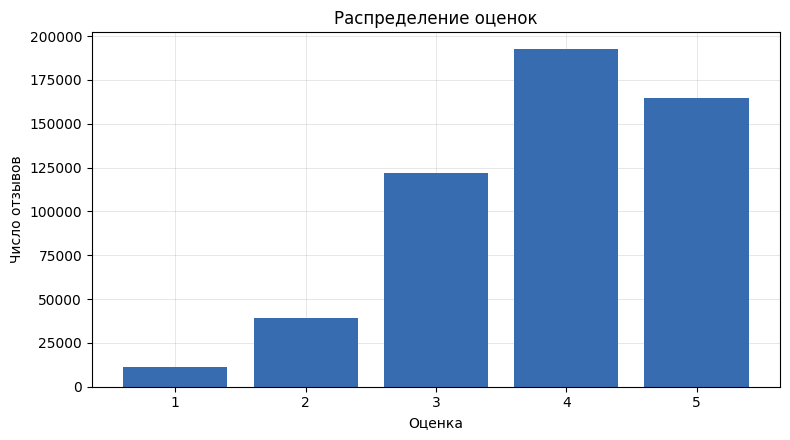

In [ ]:
e.plot_eda("ratings")


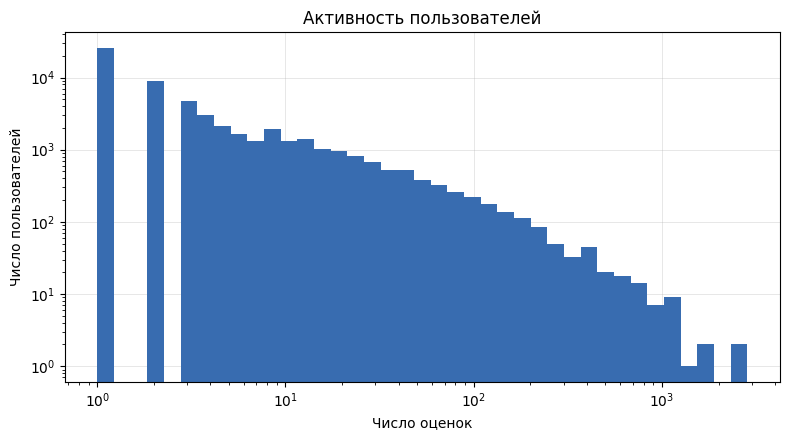

In [ ]:
e.plot_eda("activity")


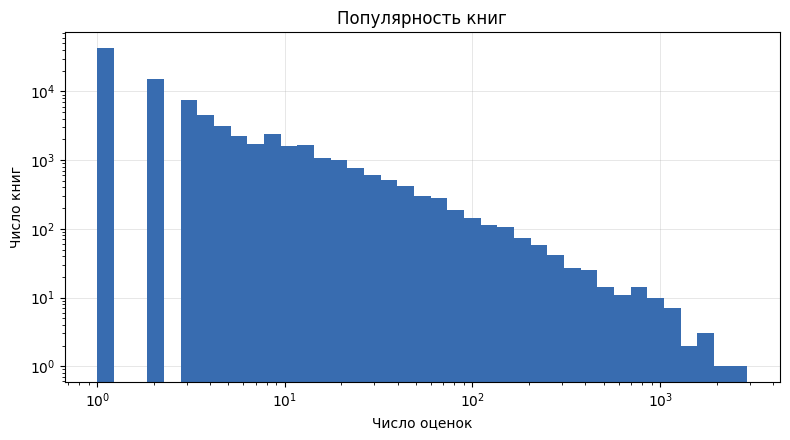

In [ ]:
e.plot_eda("popularity")


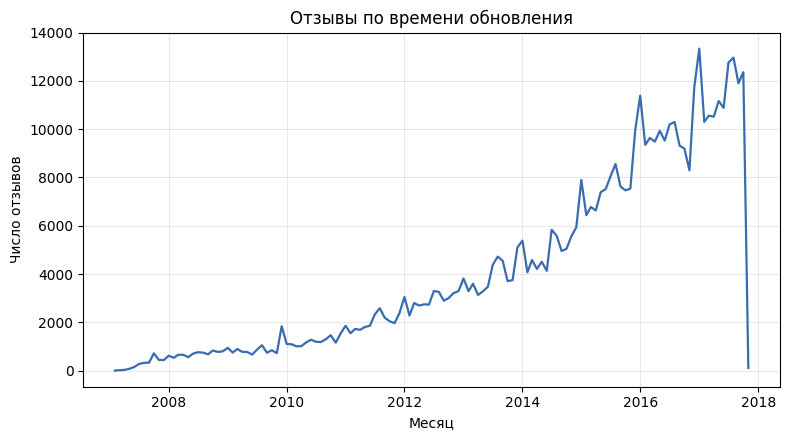

In [ ]:
e.plot_eda("time")


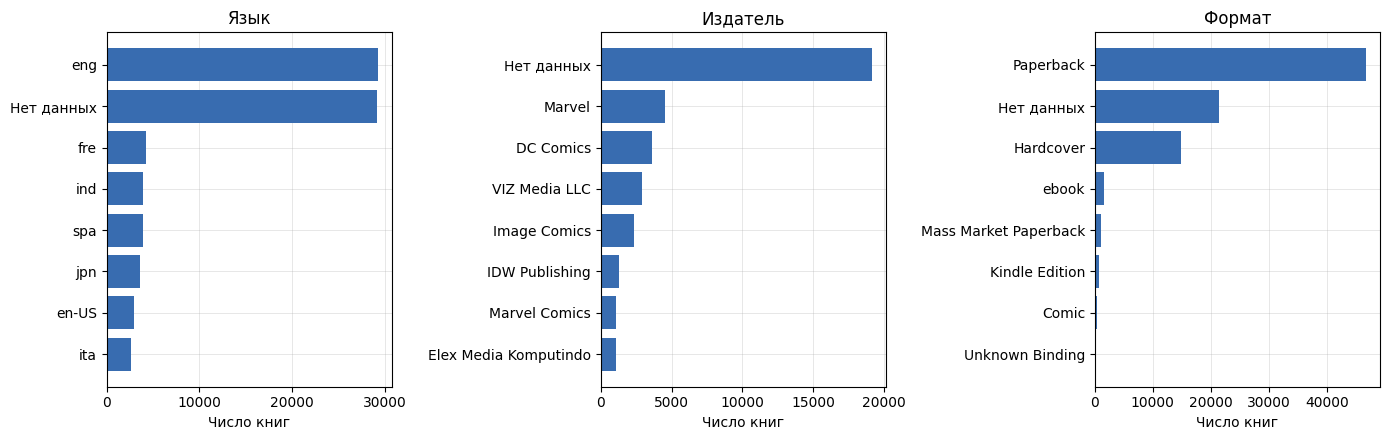

In [ ]:
e.plot_eda("metadata")


## Протокол и метрики

Разбиение глобальное по времени, примерно 70/15/15. Записи с одинаковой
временной меткой не попадают в разные периоды. Модели обучаются только на train,
настройки выбираются по validation NDCG@10. Для оценки на test выбранные
конфигурации снова обучаются на том же train.

Кандидаты включают весь каталог исходного train, около 66 тысяч книг.
Из рекомендаций исключаются все книги, которые пользователь оценивал в train,
независимо от оценки. В основную оценку входят известные пользователи,
у которых в соответствующем будущем периоде есть хотя бы одна новая
релевантная книга из этого каталога. Для всех моделей используется один
и тот же набор пользователей. Новые пользователи и книги в основную оценку
не входят, но остаются в исходных данных и учитываются в диагностике охвата.
Пользователям без положительной истории рекомендуются популярные книги.
При одинаковых прогнозах первой ставится книга с меньшим ID.

Релевантность на validation и test определяется одинаково: `rating >= 4`.
Recall@10 показывает долю найденных релевантных книг.
NDCG@10 учитывает позицию попадания с весом $1/\log_2(j+1)$
и нормируется на идеальную выдачу пользователя.

**Coverage@10** означает покрытие каталога:
$|\bigcup_u L_u^{10}|/|I_{train}|$.
В таблице ниже охват положительных пар равен доле будущих пар с оценкой
4 или 5, у которых и пользователь, и книга встречались в исходном train.


In [ ]:
with contextlib.redirect_stdout(io.StringIO()):
    protocol = describe_protocol_train_only(e)
split_rows = []
for name, frame in (("train", e.split_.train), ("validation", e.split_.validation), ("test", e.split_.test)):
    part = protocol["split"]["parts"][name]
    split_rows.append({
        "Выборка": name,
        "Начало UTC": pd.to_datetime(frame.timestamp.min(), unit="s", utc=True).strftime("%Y-%m-%d"),
        "Конец UTC": pd.to_datetime(frame.timestamp.max(), unit="s", utc=True).strftime("%Y-%m-%d"),
        "Оценки": part["rows"],
        "Пользователей в оценке": part["users_with_warm_positive"] if name != "train" else pd.NA,
        "Охват положительных пар": part["positive_pairs_known_train_user_and_item"] / max(1, part["positive_pairs"]),
    })
display(pd.DataFrame(split_rows).round(3))
print(f"Общий каталог кандидатов: {protocol['candidate_count']:,}")


,Выборка,Начало UTC,Конец UTC,Оценки,Пользователей в оценке,Охват положительных пар
0,train,2007-02-21,2016-08-22,370672,<NA>,1.000
1,validation,2016-08-22,2017-04-10,79430,7563,0.584
2,test,2017-04-10,2017-11-05,79430,5669,0.380


Общий каталог кандидатов: 66,287


## Модели и признаки

Строка матрицы соответствует пользователю, а столбец соответствует книге.
Маска всех оценок обозначается через $M$, а положительных через
$S_{ui}=\mathbf1[r_{ui}\ge4]$.

**ItemKNN.** Сходство между столбцами $S$ рассчитывается по формуле
$w_{ji}=\cos(S_j,S_i)n_{ji}/(n_{ji}+\beta)$. Диагональ исключается,
для каждой книги остаётся top-k соседей. Оценка для ранжирования равна $S_uW$.
Здесь $n_{ji}$ обозначает число общих пользователей, которые поставили
обеим книгам оценку 4 или 5.
Параметр $\beta$ задаёт силу поправки: при $\beta>0$ редкие совпадения
получают меньший вес.
Сходства строятся разреженными блоками.

**iALS.** Минимизируется функция
$\sum_{ui}c_{ui}(p_{ui}-a_u^\top b_i)^2+\lambda(\|A\|_F^2+\|B\|_F^2)$,
где $p=S$, $c=1+\alpha M$. Факторы обновляются попеременным решением систем.
Для оценок 1, 2 и 3 целевое значение равно нулю, но их вес больше,
чем у пар без оценки.
[Hu et al., 2008](https://doi.org/10.1109/ICDM.2008.22).

**SLIM.** Для каждой книги выбирается до 64 других книг с общими читателями,
поставившими обеим книгам оценку 4 или 5. Отбор основан на косинусном сходстве. Затем решается задача
$\min_{w\ge0}\frac12\|S_i-S_{C_i}w\|^2+\lambda_1\|w\|_1+
\frac{\lambda_2}{2}\|w\|^2$.
Диагональ нулевая, оценки для ранжирования равны $SW$. Используется FISTA
с ограничением числа итераций. Целевая функция и условия оптимальности KKT
проверяются только для выбранных связей между книгами.
Это ограничение коэффициентов модели, а не сокращение исходных данных.
[Ning, Karypis, 2011](https://doi.org/10.1109/ICDM.2011.134).

**FM.** Для признаков $x$ используется функция
$f(x)=w^\top x+\sum_{j<k}\langle v_j,v_k\rangle x_jx_k$ и BPR loss.
При обучении книга с оценкой 4 или 5 сравнивается со случайной неоценённой
книгой. Модель обучается ставить положительно оценённую книгу выше.
К ID добавляются автор, язык, издатель, формат, число страниц и год публикации.
Автор и язык связывают близкие книги. Остальные поля описывают издание.
Отрицательные примеры выбираются из доступного каталога вне известной истории.
При оценке рассматривается весь общий каталог.
[Rendle, 2010](https://doi.org/10.1109/ICDM.2010.127).

Категории кодируются разреженно, неизвестным значениям выделяются отдельные признаки.
При нескольких авторах веса нормируются на корень из их количества.
К числу страниц применяется log1p. Численные пропуски заполняются медианой,
затем признаки стандартизуются и ограничиваются диапазоном от -5 до 5.
Все словари и статистики рассчитываются только по train. Метаданные книг
рассматриваются как статические, поскольку их исторические версии недоступны.
Средние рейтинги, счётчики, shelves и тексты отзывов в FM не входят.

**Custom iALS.** Целевой сигнал задаётся формулой
$p^{custom}_{ui}=\max(0,(r_{ui}-2)/3)\,2^{-\mathrm{age}_{ui}/h}$.
Давность измеряется в днях от наблюдения до границы train, то есть начала
validation. Эта граница не меняется перед оценкой test.
Рейтинг 3 задаёт более слабый интерес, чем 4 и 5. Давность уменьшает
влияние старых оценок. Веса наблюдений и способ обучения остаются прежними. При $h=\infty$ остаётся
только преобразование рейтинга. Общие настройки совпадают с выбранной iALS.
Дробный сигнал используется только при обучении. При оценке всех моделей
релевантной по-прежнему считается книга с рейтингом не ниже 4.


In [ ]:
space = e.search_space()
grid_rows = []
for name, configs in space["grids"].items():
    if isinstance(configs, list):
        values = {}
        for config in configs:
            for key, value in config.items():
                if value not in values.setdefault(key, []):
                    values[key].append(value)
        count = len(configs)
    else:
        values = configs
        count = len(configs["half_life"])
    grid_rows.append({"Модель": name, "Конфигураций": count,
                      "Пространство поиска": json.dumps(values, ensure_ascii=False)})
with pd.option_context("display.max_colwidth", None):
    display(pd.DataFrame(grid_rows))
print("Всего конфигураций:", space["total_trials"])


,Модель,Конфигураций,Пространство поиска
0,ItemKNN,9,"{""k"": [50, 150, 300], ""shrink"": [0.0, 10.0, 50.0]}"
1,SLIM,6,"{""l1"": [0.1, 1.0], ""l2"": [1.0, 10.0, 100.0], ""max_candidates"": [64], ""max_iter"": [300], ""tol"": [0.0001]}"
2,IALS,27,"{""factors"": [16, 32, 64], ""reg"": [0.1, 1.0, 10.0], ""alpha"": [1.0, 10.0, 40.0], ""epochs"": [10]}"
3,FM,12,"{""factors"": [16, 32, 64], ""lr"": [0.001, 0.005], ""epochs"": [15], ""reg"": [0.0001, 0.001], ""batch_size"": [2048], ""device"": [""auto""]}"
4,CustomIALS,5,"{""base_parameters"": ""validation-selected IALS configuration"", ""half_life"": [180.0, 365.0, 730.0, 1095.0, ""inf""]}"


Всего конфигураций: 59


## Подбор на validation

Проверяются 59 конфигураций: 9 для ItemKNN, 6 для SLIM,
27 для iALS, 12 для FM и 5 значений периода полураспада для Custom iALS.
Выбирается вариант с наибольшим NDCG@10. При равенстве выбирается первый в сетке.
SLIM обучается до 300 итераций, FM обучается 15 эпох.
Ниже поиск выполняется отдельно для каждой модели. Результаты каждой конфигурации
сохраняются сразу, а строка прогресса обновляется без длинного журнала.


In [ ]:
with contextlib.redirect_stdout(io.StringIO()):
    e.validate_model("ItemKNN", plots=False, progress=show_progress)
clear_output(wait=True)
print("ItemKNN: подбор завершён")


ItemKNN: подбор завершён


In [ ]:
with contextlib.redirect_stdout(io.StringIO()):
    e.validate_model("SLIM", plots=False, progress=show_progress)
clear_output(wait=True)
print("SLIM: подбор завершён")


SLIM: подбор завершён


In [ ]:
with contextlib.redirect_stdout(io.StringIO()):
    e.validate_model("IALS", plots=False, progress=show_progress)
clear_output(wait=True)
print("IALS: подбор завершён")


IALS: подбор завершён


In [ ]:
with contextlib.redirect_stdout(io.StringIO()):
    e.validate_model("FM", plots=False, progress=show_progress)
clear_output(wait=True)
print("FM: подбор завершён")


FM: подбор завершён


In [ ]:
with contextlib.redirect_stdout(io.StringIO()):
    e.validate_model("CustomIALS", plots=False, progress=show_progress)
clear_output(wait=True)
print("CustomIALS: подбор завершён")


CustomIALS: подбор завершён


In [ ]:
validation_trials = e.validation_results_.copy()
assert len(validation_trials) == e.search_space()["total_trials"]
summary = validation_trials.groupby("model", sort=False)["NDCG@10"].agg(["size", "min", "max"])
summary["range"] = summary["max"] - summary["min"]
display(summary.rename(columns={"size": "Конфигураций", "min": "Минимум NDCG@10",
                                "max": "Максимум NDCG@10", "range": "Диапазон"}).round(6))
display(Markdown("**Выбранные параметры**"))
with pd.option_context("display.max_colwidth", None):
    display(e.validation_best_[["model", "NDCG@10", "Recall@10", "params"]].round(6))
display(Markdown("**Все проверенные конфигурации**"))
validation_trials.insert(1, "config", validation_trials.groupby("model", sort=False).cumcount() + 1)
columns = ["model", "config", "NDCG@10", "Recall@10", "fit_seconds", "selected"]
with pd.option_context("display.max_rows", 80):
    display(validation_trials[columns].round(6))


,Конфигураций,Минимум NDCG@10,Максимум NDCG@10,Диапазон
model,,,,
ItemKNN,9,0.039143,0.058442,0.019299
SLIM,6,0.052665,0.058887,0.006222
IALS,27,0.040451,0.049621,0.009171
FM,12,0.021083,0.036343,0.015260
CustomIALS,5,0.051968,0.061418,0.009450


**Выбранные параметры**

,model,NDCG@10,Recall@10,params
5,ItemKNN,0.058442,0.077778,"{""k"": 150, ""shrink"": 50.0}"
11,SLIM,0.058887,0.078293,"{""l1"": 0.1, ""l2"": 100.0, ""max_candidates"": 64, ""max_iter"": 300, ""tol"": 0.0001}"
40,IALS,0.049621,0.069517,"{""alpha"": 10.0, ""epochs"": 10, ""factors"": 64, ""reg"": 10.0}"
43,FM,0.036343,0.050789,"{""batch_size"": 2048, ""device"": ""auto"", ""epochs"": 15, ""factors"": 16, ""lr"": 0.001, ""reg"": 0.001}"
55,CustomIALS,0.061418,0.083590,"{""alpha"": 10.0, ""epochs"": 10, ""factors"": 64, ""half_life"": 365.0, ""reg"": 10.0}"


**Все проверенные конфигурации**

,model,config,NDCG@10,Recall@10,fit_seconds,selected
0,ItemKNN,1,0.040725,0.054354,4.154984,False
1,ItemKNN,2,0.055898,0.074741,4.352046,False
2,ItemKNN,3,0.057397,0.075987,4.360257,False
3,ItemKNN,4,0.039408,0.053239,4.059613,False
4,ItemKNN,5,0.056905,0.076201,4.207470,False
5,ItemKNN,6,0.058442,0.077778,4.411137,True
6,ItemKNN,7,0.039143,0.052080,4.061964,False
7,ItemKNN,8,0.056784,0.076224,4.477832,False
8,ItemKNN,9,0.058032,0.077006,4.553487,False
9,SLIM,1,0.052665,0.071797,180.956256,False


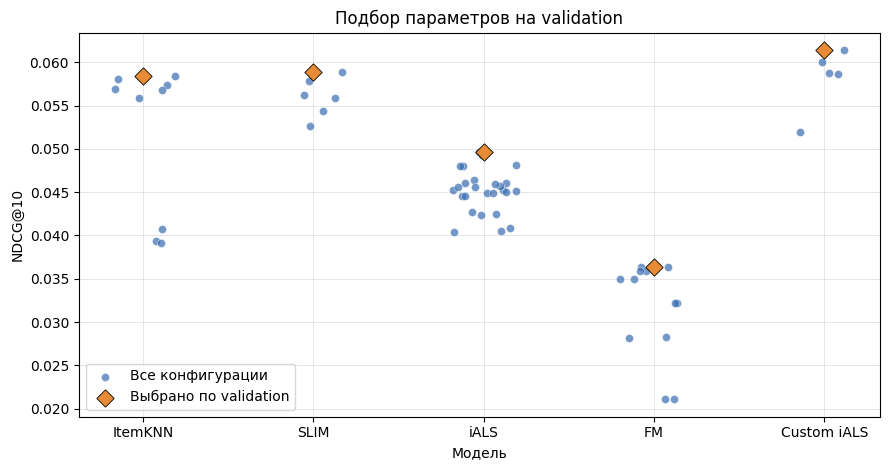

In [ ]:
e.plot_validation()


## Финальное сравнение

Выбранные модели обучаются только на train и оцениваются на test.
Каталог, признаки книг и маска известных оценок строятся по исходному train.
Validation используется только для выбора настроек.

Для сравнения добавлены рекомендации по популярности, FM только с ID
и Custom iALS без затухания. У двух последних вариантов используются те же
настройки, что у соответствующих основных моделей. Это позволяет отдельно
оценить вклад метаданных и давности оценок.
Test не используется в обучении и подборе параметров, но этот период
уже просматривался в предварительном прогоне.


In [ ]:
with contextlib.redirect_stdout(io.StringIO()):
    final_e = final_evaluate_train_only(e, plots=False, progress=show_progress)
final_results = final_e.final_results_.copy()
clear_output(wait=True)
main_names = ["ItemKNN", "IALS", "SLIM", "FM", "CustomIALS"]
columns = ["model", "NDCG@10", "Recall@10", "Coverage@10", "fit_seconds", "params"]
with pd.option_context("display.max_colwidth", None):
    display(final_results.loc[final_results.model.isin(main_names), columns].round(6))
    display(final_results.loc[~final_results.model.isin(main_names), columns].round(6))


,model,NDCG@10,Recall@10,Coverage@10,fit_seconds,params
0,ItemKNN,0.037140,0.055435,0.136407,4.326345,"{""k"": 150, ""shrink"": 50.0}"
1,SLIM,0.035891,0.053798,0.152715,51.745119,"{""l1"": 0.1, ""l2"": 100.0, ""max_candidates"": 64, ""max_iter"": 300, ""tol"": 0.0001}"
2,IALS,0.034393,0.053515,0.014709,67.094830,"{""alpha"": 10.0, ""epochs"": 10, ""factors"": 64, ""reg"": 10.0}"
3,FM,0.036144,0.052992,0.003530,14.805827,"{""batch_size"": 2048, ""device"": ""auto"", ""epochs"": 15, ""factors"": 16, ""lr"": 0.001, ""reg"": 0.001}"
4,CustomIALS,0.037499,0.056999,0.015252,67.177121,"{""alpha"": 10.0, ""epochs"": 10, ""factors"": 64, ""half_life"": 365.0, ""reg"": 10.0}"


,model,NDCG@10,Recall@10,Coverage@10,fit_seconds,params
5,Popularity,0.038642,0.059023,0.000422,0.000000,{}
6,FM_ID,0.034013,0.051907,0.004767,8.390420,"{""batch_size"": 2048, ""device"": ""auto"", ""epochs"": 15, ""factors"": 16, ""lr"": 0.001, ""reg"": 0.001}"
7,CustomRatingOnly,0.035052,0.053457,0.015855,66.265526,"{""alpha"": 10.0, ""epochs"": 10, ""factors"": 64, ""half_life"": ""inf"", ""reg"": 10.0}"


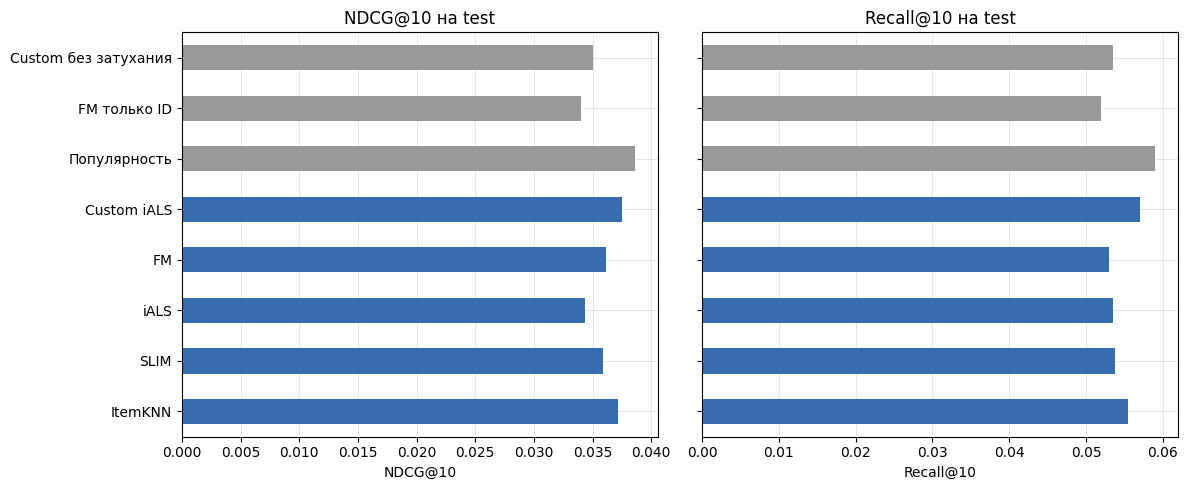

In [ ]:
final_e.plot_test_metrics()


Ниже показаны обучающие функции потерь. Их значения у разных моделей
напрямую не сравниваются и сами по себе не показывают качество рекомендаций.


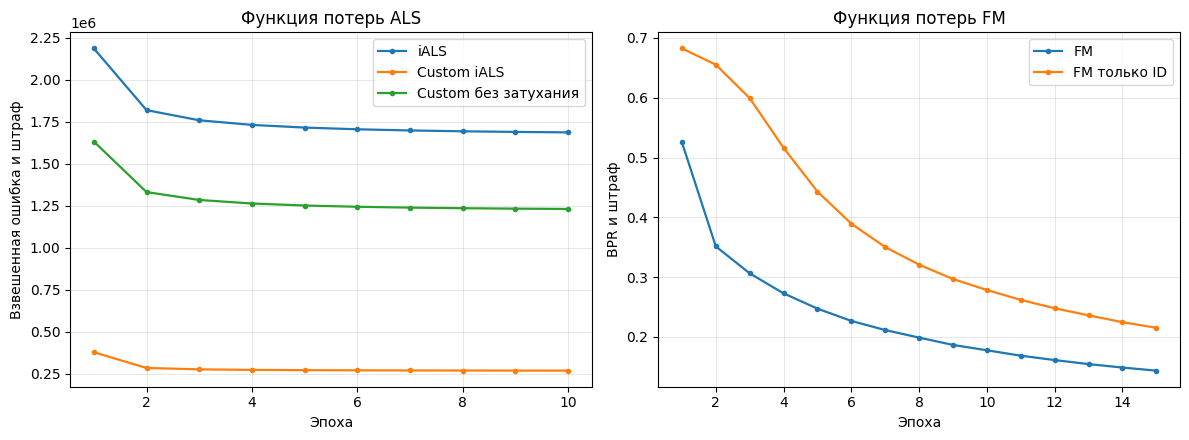

In [ ]:
final_e.plot_training_losses()


Показан пример top-10 модели Custom iALS, выбранной по validation.
`future_relevant` отмечает книги с положительной оценкой в test.


In [ ]:
with contextlib.redirect_stdout(io.StringIO()):
    examples = final_e.example_recommendations()
user = examples.user_id.iloc[0]
print("Пример рекомендаций для пользователя", user)
display(examples.loc[examples.user_id.eq(user), ["rank", "title", "future_relevant"]])


Пример рекомендаций для пользователя 49


,rank,title,future_relevant
0,1,"March: Book One (March, #1)",False
1,2,"Ms. Marvel, Vol. 1: No Normal",False
2,3,"Step Aside, Pops (Hark! A Vagrant, #3)",False
3,4,Roller Girl,False
4,5,El Deafo,False
5,6,Rosalie Lightning: A Graphic Memoir,False
6,7,Fun Home: A Family Tragicomic,False
7,8,"Adulthood Is a Myth (Sarah's Scribbles, #1)",False
8,9,The Arrival,False
9,10,Drowned City: Hurricane Katrina and New Orleans,False


## Выводы

На test рекомендации по популярности оказались выше всех моделей: NDCG@10 **0.038642**, Recall@10 **0.059023**. При этом они покрывают только **0.0422%** каталога. Среди пяти основных моделей лучший результат у Custom iALS: **0.037499** и **0.056999** соответственно. ItemKNN близок к нему с **0.037140** и **0.055435**. По охвату каталога ItemKNN и SLIM заметно шире популярности: **13.64%** и **15.27%**. Получается, что рекомендации по популярности точнее на этом test, но предлагают читателям очень узкий набор книг.

В ItemKNN поправка на число общих читателей повлияла на результат сильнее, чем увеличение списка соседей. При k=150 переход от shrink=0 к shrink=50 повысил validation NDCG@10 с **0.039408** до **0.058442**. Дальнейшее увеличение k до 300 дало **0.058032**. В SLIM при l1=0.1 увеличение l2 с 1 до 100 повысило NDCG@10 с **0.052665** до **0.058887**. В проверенной сетке регуляризация помогла обоим соседским методам. При этом лучшие значения части параметров лежат на границах сетки, поэтому более широкий поиск ещё может изменить результат.

У iALS при одинаковых reg и alpha увеличение числа факторов с 16 до 64 повысило validation NDCG@10 с **0.045125** до **0.049621**. Увеличение веса известных оценок не давало постоянного выигрыша: alpha=10 оказалось лучше и 1, и 40. У FM при одинаковых остальных настройках рост размерности с 16 до 64 снизил NDCG@10 с **0.036343** до **0.034942**. При 16 факторах lr=0.001 дал более высокий результат, чем lr=0.005. Разница между двумя значениями регуляризации при лучшем learning rate была небольшой. Большее число факторов здесь само по себе не улучшало ранжирование.

Добавление метаданных повысило test NDCG@10 FM с **0.034013** до **0.036144** при одинаковых настройках. Прирост составил **+0.002131**. На этом разбиении выбранные признаки помогли FM, хотя по основным метрикам она осталась ниже рекомендаций по популярности. Такой эксперимент показывает вклад метаданных в выбранную конфигурацию. Вариант только с ID отдельно не настраивался.

Новый таргет повысил test NDCG@10 относительно обычной iALS с **0.034393** до **0.037499**, то есть на **+0.003107**. Вариант, который учитывает величину рейтинга без затухания, дал **0.035052**. Добавление давности оценок повысило результат ещё на **+0.002447**. Лучший период полураспада на validation составил 365 дней. В этом эксперименте учёт рейтинга и времени оказался полезен, но это результат одного разбиения и одного seed.

Выбранный SLIM достиг критерия остановки во всех 49745 оптимизируемых подзадачах. При этом модель по-прежнему использует не более 64 связей на книгу, и проверка KKT относится именно к этим связям. На использованном оборудовании ItemKNN обучился примерно за 4.3 секунды против 51.7 секунды у SLIM. С учётом близких метрик и широкого охвата каталога ItemKNN оказался удачным простым вариантом. Все финальные модели обучены только на train, а validation использована для выбора настроек.
